# F3.6 — Control de permutación de los finalistas

Figuras de apoyo de la tarea F3.6 (`docs/bitacora/F3.6.md`, matriz §7). Cada finalista se reentrenó con las etiquetas de **entrenamiento** permutadas (`default_rng(99)`), con los hiperparámetros de F3.4 y las cinco semillas de F3.5. Validación y prueba conservan las etiquetas reales, y la parada temprana usa el F1-val real.

Reglas que sigue este notebook:

- **Toda cifra se lee de archivos versionados:** `results/f36_permutacion/<técnica>/runs/*.json` y, como referencia, los modelos reales de `results/f35_final/`.
- **Es descriptivo.** El piso «visual permutado» (media de las cinco semillas) y su contraste los calcula SV en F5.1 con el *bootstrap* pareado preregistrado.
- `y_hat = 1` si y solo si `p_dep > 0.5` (F1.5 §3.3). La DE entre semillas usa `ddof=1`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / 'src'))
from viz import style

style.apply()
RES = REPO / 'results' / 'f36_permutacion'
REAL = REPO / 'results' / 'f35_final'
FIG = RES / 'figures'
TECHS = ['gray_scott', 'perlin', 'lorenz']
STEM = {'gray_scott': 'gray_scott__efficientnet_b0__finetune__px224-flip',
        'perlin': 'perlin__vit_b16__frozen__px224-noflip', 'lorenz': 'lorenz__vit_b16__frozen__px224-noflip'}
CFG_LABEL = {'gray_scott': 'EfficientNet-B0 fine-tuning', 'perlin': 'ViT-B/16 congelado', 'lorenz': 'ViT-B/16 congelado'}
SEEDS = [42, 7, 123, 2024, 99]

def label(tech):
    return f'{style.TECH_LABEL[tech]} · {CFG_LABEL[tech]}'

def f1_macro(y, y_hat):
    f1 = []
    for k in (0, 1):
        tp = np.sum((y_hat == k) & (y == k)); fp = np.sum((y_hat == k) & (y != k)); fn = np.sum((y_hat != k) & (y == k))
        f1.append(2 * tp / (2 * tp + fp + fn))
    return float(np.mean(f1))

def auc(y, p):
    order = np.argsort(p); r = np.empty(len(p)); r[order] = np.arange(1, len(p) + 1)
    for v in np.unique(p):                       # rangos promedio en empates
        m = p == v; r[m] = r[m].mean()
    n1 = y.sum(); n0 = len(y) - n1
    return float((r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n0 * n1))

## Insumos

Se verifica la fase, que `permutation_indices` sea `default_rng(99).permutation(908)` en las 15 corridas, que val y prueba tengan las etiquetas reales de F3.5, y que el F1 recalculado coincida con el registrado.

In [2]:
PERM = [int(i) for i in np.random.default_rng(99).permutation(908)]
perm, real = {}, {}
for tech in TECHS:
    assert json.loads((RES / tech / 'grid_meta.json').read_text(encoding='utf-8')) == {'fase': 'control_permutacion', 'smoke': False}
    for s in SEEDS:
        d = json.loads((RES / tech / 'runs' / f'{STEM[tech]}-perm99__seed{s}.json').read_text(encoding='utf-8'))
        e = json.loads((REAL / tech / 'runs' / f'{STEM[tech]}__seed{s}.json').read_text(encoding='utf-8'))
        assert d['permute_labels'] == 99 and d['permutation_indices'] == PERM
        assert d['val_true'] == e['val_true'] and d['test_true'] == e['test_true']
        for split, key in (('val', 'best_f1_val'), ('test', 'f1_test')):
            assert abs(f1_macro(np.array(d[f'{split}_true']), (np.array(d[f'{split}_probs']) > 0.5).astype(int)) - d[key]) < 1e-12
        perm[(tech, s)], real[(tech, s)] = d, e

y_test = np.array(perm[('gray_scott', 42)]['test_true'])
rows = []
for tech in TECHS:
    p_real = np.mean([real[(tech, s)]['test_probs'] for s in SEEDS], axis=0)
    for s in SEEDS:
        d = perm[(tech, s)]; p = np.array(d['test_probs'])
        rows.append(dict(technique=tech, seed=s, best_epoch=d['best_epoch'], epochs_run=d['epochs_run'],
                         f1_val=d['best_f1_val'], f1_test=d['f1_test'], f1_test_real=real[(tech, s)]['f1_test'],
                         auc_test=auc(y_test, p), frac_pred_dep=float((p > 0.5).mean()),
                         corr_con_finalista=float(np.corrcoef(p, p_real)[0, 1])))
per_run = pd.DataFrame(rows)
resumen = per_run.groupby('technique', sort=False).agg(
    f1_test_media=('f1_test', 'mean'), f1_test_de=('f1_test', lambda x: x.std(ddof=1)),
    f1_test_min=('f1_test', 'min'), f1_test_max=('f1_test', 'max'),
    f1_test_real_media=('f1_test_real', 'mean'), auc_media=('auc_test', 'mean'),
    corr_positivas=('corr_con_finalista', lambda x: int((x > 0).sum())))
print('15 corridas verificadas (permutación, etiquetas reales en val/test, F1 recalculado)')
per_run.round(3)

15 corridas verificadas (permutación, etiquetas reales en val/test, F1 recalculado)


,technique,seed,best_epoch,epochs_run,f1_val,f1_test,f1_test_real,auc_test,frac_pred_dep,corr_con_finalista
0,gray_scott,42,2,6,0.533,0.566,0.745,0.603,0.351,0.454
1,gray_scott,7,2,6,0.458,0.467,0.727,0.444,0.281,-0.140
2,gray_scott,123,1,5,0.514,0.427,0.698,0.405,0.474,-0.307
3,gray_scott,2024,1,5,0.587,0.719,0.737,0.745,0.561,0.651
4,gray_scott,99,3,7,0.434,0.455,0.719,0.457,0.649,0.050
5,perlin,42,1,5,0.490,0.550,0.658,0.556,0.105,0.448
6,perlin,7,5,9,0.537,0.642,0.690,0.683,0.237,0.594
7,perlin,123,15,15,0.487,0.559,0.686,0.556,0.289,0.160
8,perlin,2024,1,5,0.452,0.471,0.660,0.445,0.079,0.172
9,perlin,99,4,8,0.619,0.519,0.665,0.561,0.491,0.243


In [3]:
resumen.round(4)

,f1_test_media,f1_test_de,f1_test_min,f1_test_max,f1_test_real_media,auc_media,corr_positivas
technique,,,,,,,
gray_scott,0.5270,0.1192,0.4273,0.7185,0.7250,0.5306,3
perlin,0.5483,0.0626,0.4715,0.6421,0.6719,0.5603,5
lorenz,0.5329,0.0419,0.4911,0.5914,0.7307,0.5906,5


## Referencia de azar

Distribución del F1-macro de prueba de un clasificador que **no mira la imagen** y predice «depresivo» con probabilidad 44/114, la prevalencia de prueba. Se simula con 20,000 réplicas sobre las mismas 114 etiquetas reales. Es solo una referencia visual. El piso del protocolo no se calcula aquí.

In [4]:
rng = np.random.default_rng(2026)
prev = y_test.mean()
null = np.array([f1_macro(y_test, (rng.random(len(y_test)) < prev).astype(int)) for _ in range(20000)])
lo, hi = np.quantile(null, [0.025, 0.975])
print(f'azar: media {null.mean():.4f}, DE {null.std(ddof=1):.4f}, intervalo central 95 % [{lo:.4f}, {hi:.4f}]')
per_run['p_azar_ge'] = [(null >= f).mean() for f in per_run.f1_test]
per_run[['technique', 'seed', 'f1_test', 'p_azar_ge']].round(4)

azar: media 0.4989, DE 0.0469, intervalo central 95 % [0.4078, 0.5908]


,technique,seed,f1_test,p_azar_ge
0,gray_scott,42,0.5665,0.0787
1,gray_scott,7,0.4671,0.7526
2,gray_scott,123,0.4273,0.9388
3,gray_scott,2024,0.7185,0.0000
4,gray_scott,99,0.4555,0.8232
5,perlin,42,0.5502,0.1370
6,perlin,7,0.6421,0.0010
7,perlin,123,0.5588,0.1040
8,perlin,2024,0.4715,0.7234
9,perlin,99,0.5191,0.3257


## Figura 1. F1-prueba del control frente al modelo real

Un renglón por finalista. Los puntos llenos son las cinco semillas del control (etiquetas permutadas); los huecos, las mismas semillas del modelo real de F3.5. Las marcas verticales son las medias. La banda gris es el intervalo central del 95 % del clasificador de azar de arriba. Con 114 muestras, una semilla aislada puede salir de la banda, como se ve en la sección «Parada temprana».

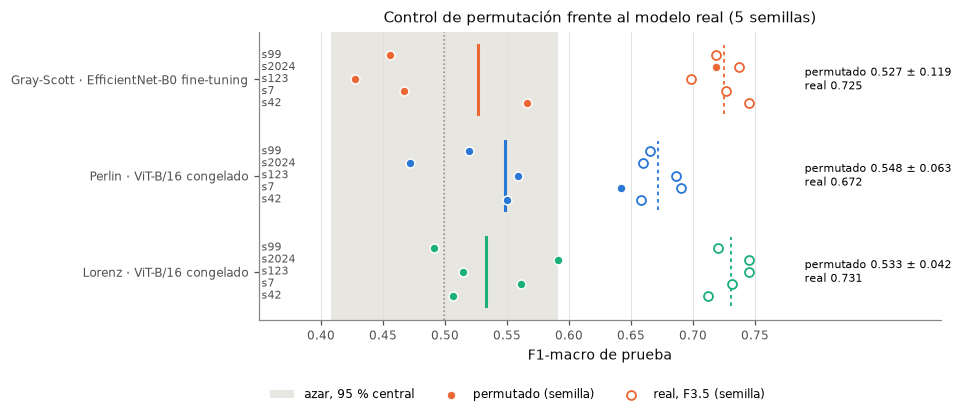

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.axvspan(lo, hi, color=style.GRID, alpha=0.8, lw=0, label='azar, 95 % central')
ax.axvline(null.mean(), color=style.MUTED, lw=1, ls=':')
OFFS = dict(zip(SEEDS, np.linspace(-0.25, 0.25, len(SEEDS))))
for i, tech in enumerate(TECHS):
    color = style.TECH_COLOR[tech]; y0 = len(TECHS) - 1 - i
    d = per_run[per_run.technique == tech]
    for _, r in d.iterrows():
        y = y0 + OFFS[r.seed]
        ax.scatter(r.f1_test, y, s=34, color=color, edgecolors=style.SURFACE, linewidths=1, zorder=3,
                   label='permutado (semilla)' if (i == 0 and r.seed == SEEDS[0]) else None)
        ax.scatter(r.f1_test_real, y, s=34, facecolors='white', edgecolors=color, linewidths=1.2, zorder=3,
                   label='real, F3.5 (semilla)' if (i == 0 and r.seed == SEEDS[0]) else None)
        ax.text(0.352, y, f's{r.seed}', va='center', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
    m = resumen.loc[tech]
    ax.plot([m.f1_test_media] * 2, [y0 - 0.36, y0 + 0.36], color=color, lw=2)
    ax.plot([m.f1_test_real_media] * 2, [y0 - 0.36, y0 + 0.36], color=color, lw=1.2, ls=(0, (2, 2)))
    ax.text(0.79, y0, f'permutado {m.f1_test_media:.3f} ± {m.f1_test_de:.3f}\nreal {m.f1_test_real_media:.3f}',
            va='center', fontsize=style.FONT_SIZES['annot'])
ax.set_yticks(range(len(TECHS))); ax.set_yticklabels([label(t) for t in reversed(TECHS)])
ax.set_xlim(0.35, 0.90); ax.set_xticks(np.arange(0.4, 0.78, 0.05))
ax.set_xlabel('F1-macro de prueba'); ax.grid(axis='x')
ax.set_title('Control de permutación frente al modelo real (5 semillas)')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.2), ncol=3)
style.save(fig, FIG / 'f1_permutado_vs_real')
plt.show()

## Figura 2. Parada temprana y parecido con el finalista

La parada temprana del control usa el F1-val con etiquetas **reales** (matriz §7), así que puede elegir una época en la que el modelo todavía no aprendió la permutación y conserva estructura de la imagen correlacionada con la clase. **Izquierda:** mejor época de cada corrida (el modelo guardado y evaluado). **Derecha:** correlación de Pearson entre su `p_dep` de prueba y la media de `p_dep` del finalista real (cinco semillas de F3.5), contra su F1 de prueba; se etiquetan (semilla · época) las corridas fuera de la banda de azar. Una correlación alta indica que el control predice parecido al modelo real.

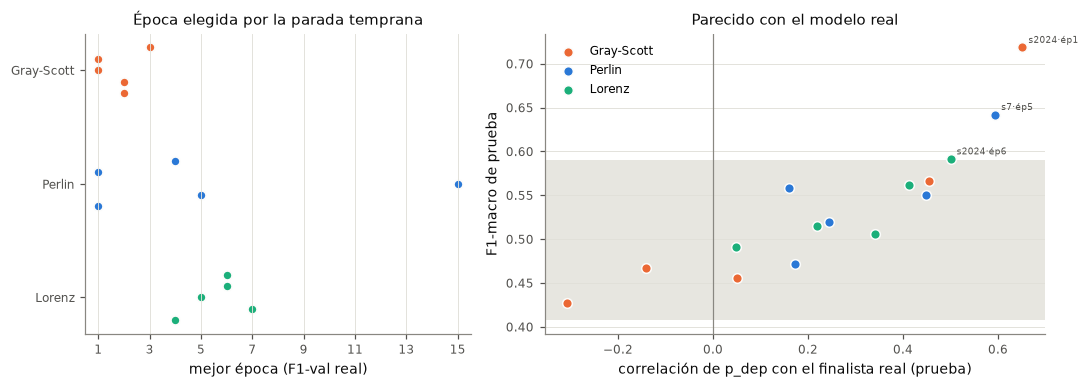

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1, 1.3]})
ax = axes[0]
for i, tech in enumerate(TECHS):
    d = per_run[per_run.technique == tech]
    ax.scatter(d.best_epoch, np.full(len(d), len(TECHS) - 1 - i) + np.linspace(-0.2, 0.2, len(d)), s=34,
               color=style.TECH_COLOR[tech], edgecolors=style.SURFACE, linewidths=1)
ax.set_yticks(range(len(TECHS))); ax.set_yticklabels([style.TECH_LABEL[t] for t in reversed(TECHS)])
ax.set_xticks(range(1, 16, 2)); ax.set_xlim(0.5, 15.5); ax.set_xlabel('mejor época (F1-val real)'); ax.grid(axis='x')
ax.set_title('Época elegida por la parada temprana')
ax = axes[1]
for tech in TECHS:
    d = per_run[per_run.technique == tech]
    ax.scatter(d.corr_con_finalista, d.f1_test, s=40, color=style.TECH_COLOR[tech], edgecolors=style.SURFACE,
               linewidths=1, label=style.TECH_LABEL[tech], zorder=3)
    for _, r in d[(d.f1_test < lo) | (d.f1_test > hi)].iterrows():
        ax.annotate(f's{r.seed}·ép{r.best_epoch}', (r.corr_con_finalista, r.f1_test), xytext=(4, 3),
                    textcoords='offset points', fontsize=style.FONT_SIZES['annot'] - 1, color=style.INK_SECONDARY)
ax.axhspan(lo, hi, color=style.GRID, alpha=0.8, lw=0)
ax.axvline(0, color=style.MUTED, lw=0.8)
ax.set_xlabel('correlación de p_dep con el finalista real (prueba)'); ax.set_ylabel('F1-macro de prueba')
ax.grid(axis='y'); ax.legend(loc='upper left')
ax.set_title('Parecido con el modelo real')
fig.tight_layout()
style.save(fig, FIG / 'parada_temprana_y_parecido')
plt.show()